# Module 2 — Pupil segmentation and mathematical morphology
Compare Otsu, K-means (K=2–5), active contours and marker-controlled watershed on both selected frames. Seeds and the snake initialization are ROI-local and configurable. Snakes are a provisional choice, not a validated winner.

Other recordings are assumed suitable and free of the large reflection seen in A_1. This notebook still shows failures on A_1 rather than assuming that its reflections have been removed.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if not (ROOT / "config.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from psib.config import load_config
from psib import video_io as vio, roi as R
from psib.calibration import select_points, pixels_per_cm
from psib.segmentation import segment_methods, morphology_variants, overlap_metrics, mask_measurements, polygon_mask
from psib.plotting import show_grid, save_fig
cfg = load_config(ROOT / "config.yaml")
m2 = cfg["module2"]
out = cfg["_output_dir"] / "module2"
out.mkdir(exist_ok=True)


## 2.0 Ruler calibration
Enable `calibration.enabled` for a video containing a ruler. With `mode: interactive`, click two ruler marks exactly 1 cm apart, then press Enter (R resets, Esc cancels). The selection window requires desktop OpenCV. Alternatively enter their full-frame coordinates in `points_xy` and use `mode: manual`.

Calibration is per video, on the upright full-resolution frame. Length = pixels / pixels_per_cm; area = pixels² / pixels_per_cm². The ruler must be in approximately the same plane as the eye; perspective and camera motion can invalidate a fixed scale. No physical units are reported without calibration. A_1 is left uncalibrated.

Ruler endpoints (paste into config.yaml): [(238.40883977900552, 486.4), (302.49723756906076, 488.96)]
Scale: 64.140 pixels/cm; 6.414 pixels/mm


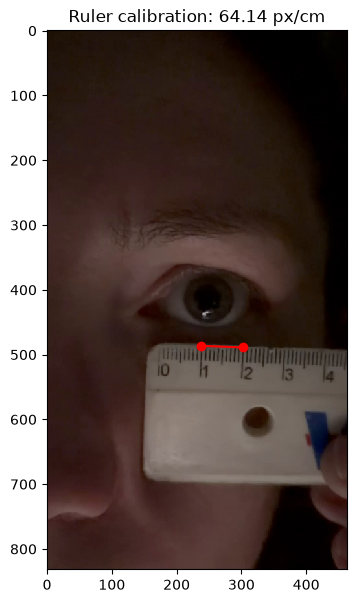

308

In [2]:
import json
cal = cfg["calibration"]
scale = None
if cal["enabled"]:
    calibration_frame, cal_time, _ = vio.read_frame_at_time(cfg["video_path"], cal["frame_time_s"])
    if cal["mode"] == "interactive":
        points = select_points(calibration_frame, title=f"Select ruler endpoints {cal['distance_cm']} cm apart")
    elif cal["mode"] == "manual":
        points = cal["points_xy"]
    else:
        raise ValueError("Unknown calibration mode")
    scale = pixels_per_cm(points, cal["distance_cm"])
    print("Ruler endpoints (paste into config.yaml):", points)
    print(f"Scale: {scale:.3f} pixels/cm; {scale / 10:.3f} pixels/mm")
    fig, ax = plt.subplots(figsize=(6, 7))
    ax.imshow(calibration_frame)
    ax.plot(*np.asarray(points).T, "ro-")
    ax.set_title(f"Ruler calibration: {scale:.2f} px/cm")
    save_fig(fig, "m2_calibration", cfg); plt.show()
    record = {"video_path": str(cfg["video_path"]), "timestamp_s": cal_time,
              "points_xy": points, "distance_cm": cal["distance_cm"], "pixels_per_cm": scale,
              "frame_shape": list(calibration_frame.shape)}
else:
    print("No ruler calibration: measurements remain in pixels.")
    record = {"video_path": str(cfg["video_path"]), "pixels_per_cm": None}
(out / "calibration.json").write_text(json.dumps(record, indent=2))


## 2.1 Segmentation comparison
Inspect the initial pupil seed and circle before interpreting the outputs. Adjust `initializations` for this video. Watershed uses an inner pupil marker and an outer background marker; snakes use the circle as their starting contour.

Selected ROI -> paste in config.yaml:  x: 155  y: 356  w: 193  h: 110
Frame 0 pupil initialization (ROI-local; save in config.yaml): {'center_xy': [93.02600000000001, 55.96491228070175], 'radius_px': 21.547802901605227}


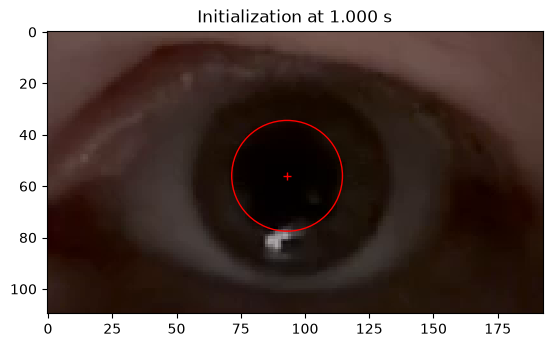

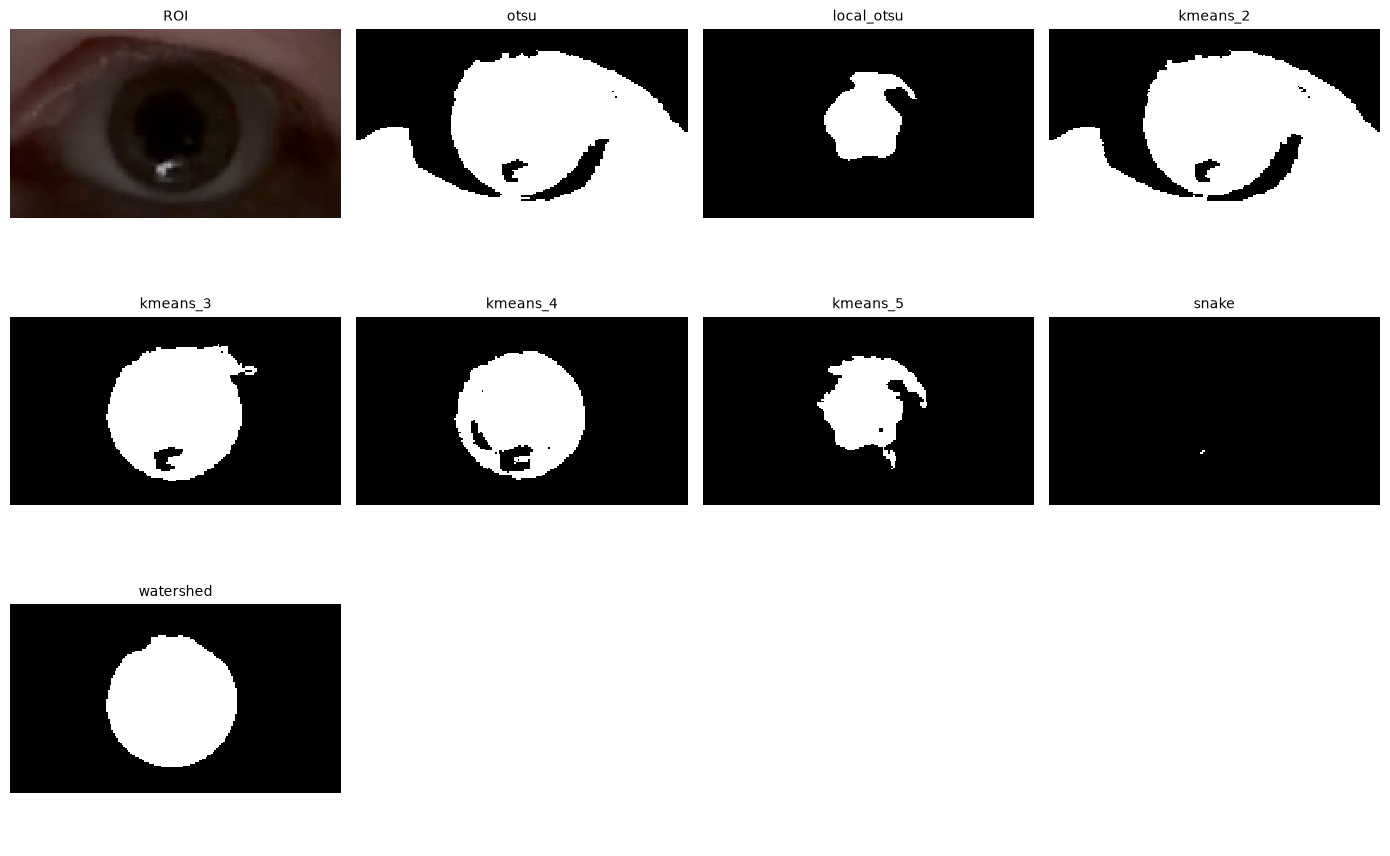

Frame 1 pupil initialization (ROI-local; save in config.yaml): {'center_xy': [95.342, 51.91228070175439], 'radius_px': 8.51148662371658}


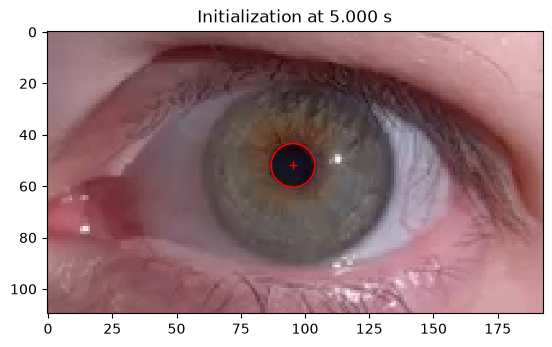

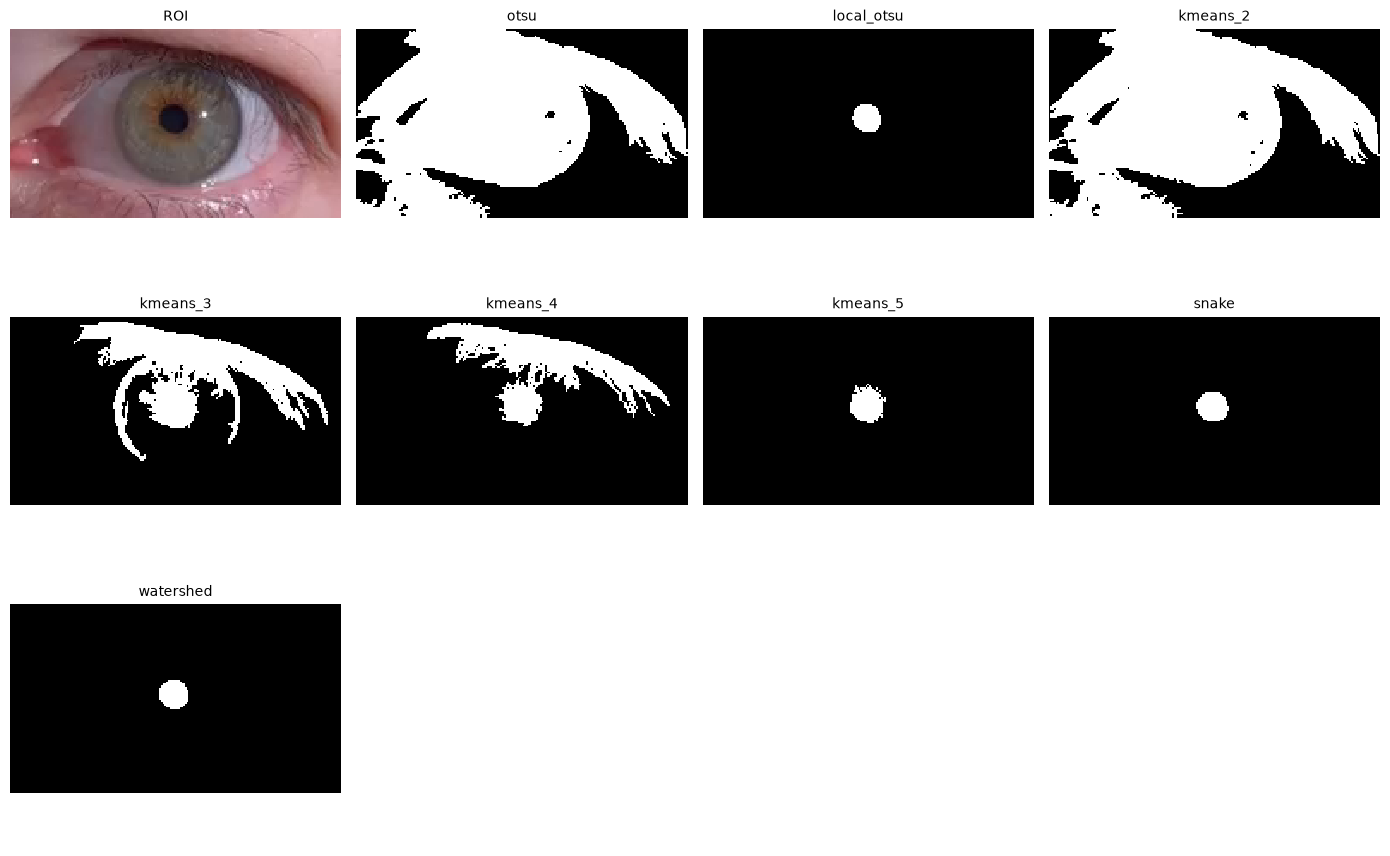

In [3]:
times = [cfg["frames"]["primary_time_s"], cfg["frames"]["secondary_time_s"]]
if len(m2["initializations"]) != len(times) or len(m2["reference_masks"]) != len(times):
    raise ValueError("Provide one initialization and reference entry per selected frame")
frames = vio.read_frames_at_times(cfg["video_path"], times)
roi = R.get_roi(cfg, frames[0][0])
tracked = R.tracked_frame_rois(frames, roi, cfg["module3"].get("eye_tracking", {}), cfg["video_path"])
all_masks, all_rois, rows = [], [], []
for index, ((frame, timestamp, frame_index), init) in enumerate(zip(frames, m2["initializations"])):
    rgb = tracked[index][0]
    init = R.pupil_initialization(cfg, rgb, index)
    all_rois.append(rgb)
    fig, ax = plt.subplots()
    ax.imshow(rgb); ax.plot(*init["center_xy"], "r+")
    ax.add_patch(plt.Circle(init["center_xy"], init["radius_px"], fill=False, color="red"))
    ax.set_title(f"Initialization at {timestamp:.3f} s")
    save_fig(fig, f"m2_initialization_{index}", cfg); plt.show()
    masks = segment_methods(rgb, **init, clusters=m2["clusters"], snake_iterations=m2["snake_iterations"])
    all_masks.append(masks)
    fig = show_grid([rgb] + list(masks.values()), ["ROI"] + list(masks), ncols=4, cell=(3.5, 3))
    save_fig(fig, f"m2_segmentations_{index}", cfg); plt.show()
    for method, mask in masks.items():
        np.save(out / f"frame_{index}_{method}.npy", mask)
        rows.append({"frame_index": frame_index, "timestamp_s": timestamp, "method": method,
                     "stage": "raw", **mask_measurements(mask, scale)})


## 2.2 Mathematical morphology
Erosion, dilation, opening and closing are compared individually. The provisional cleanup uses opening → closing → small-component removal → hole filling. Hole filling may incorrectly include bright iris regions if the initial mask is wrong; verify the overlays. Skeletonization is applied to the contour, not the filled pupil. Do not use skeleton area as pupil area.

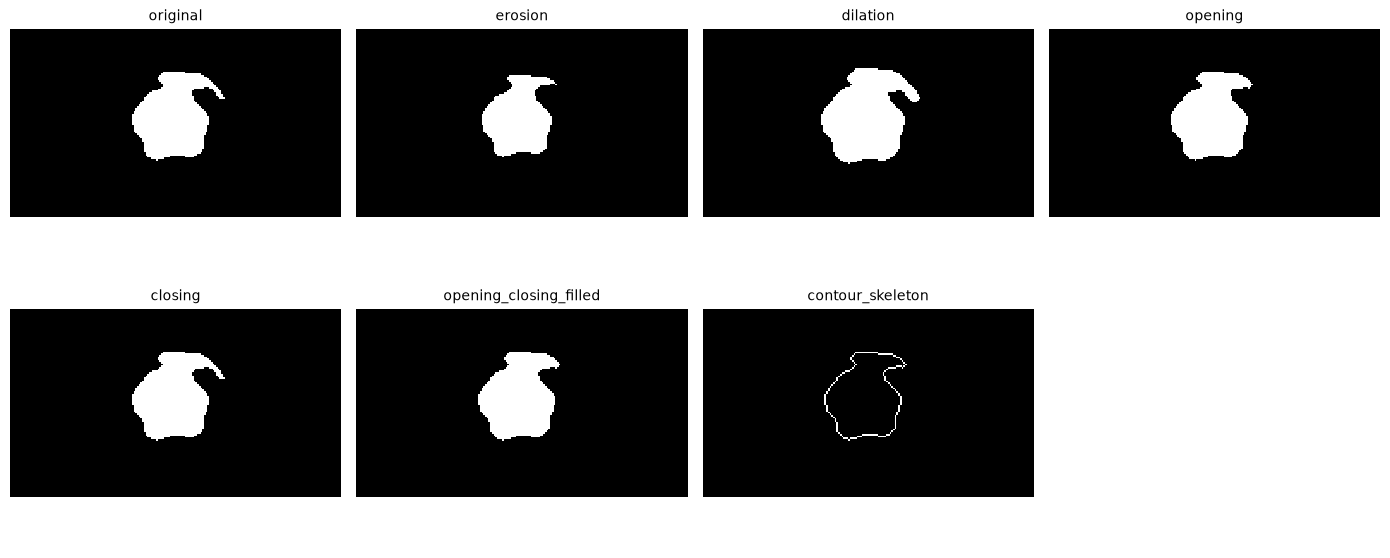

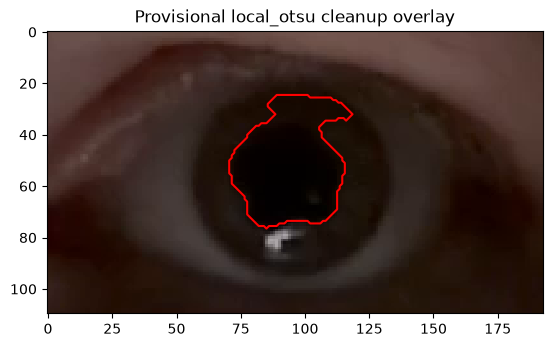

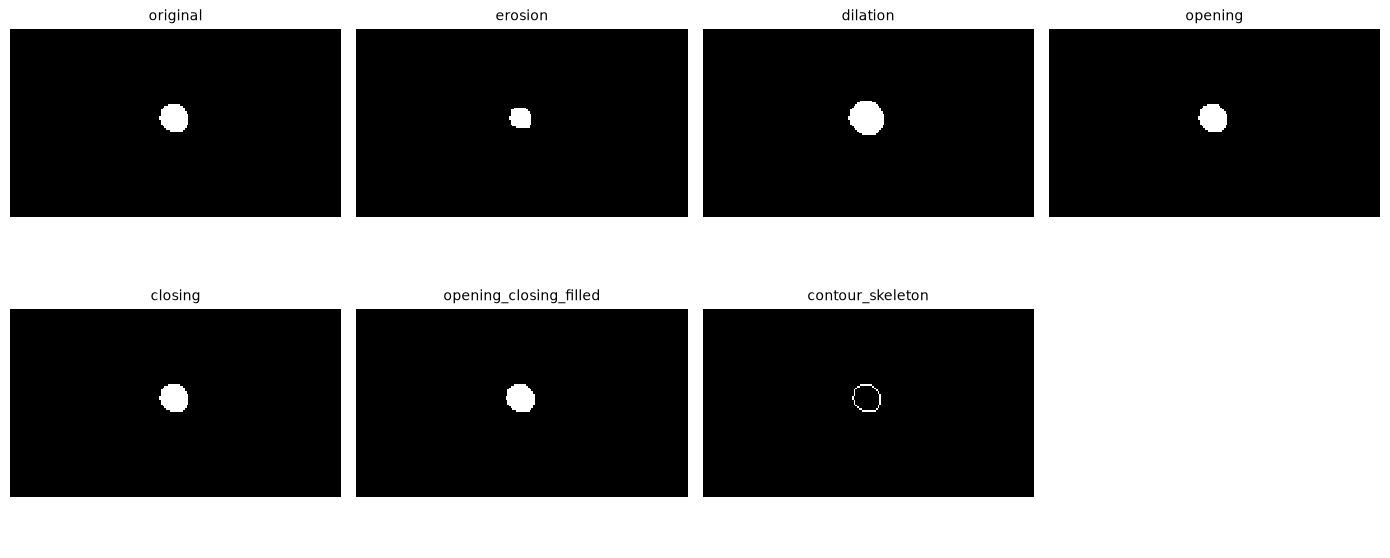

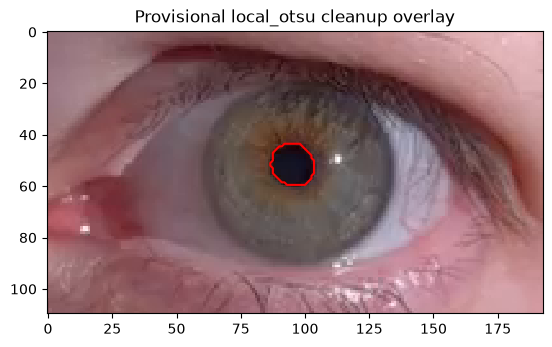

,frame_index,timestamp_s,method,stage,area_px2,perimeter_px,equivalent_diameter_px,area_cm2,area_mm2,perimeter_mm,equivalent_diameter_mm,centroid_x_px,centroid_y_px,valid
0,30,1.0,otsu,raw,12958.0,1001.621320,128.447024,3.149827,314.982731,156.162928,20.026195,104.559500,68.624711,True
1,30,1.0,local_otsu,raw,1740.0,227.414214,47.068427,0.422959,42.295875,35.456184,7.338445,94.802299,50.894253,True
2,30,1.0,kmeans_2,raw,12799.0,1034.863961,127.656543,3.111178,311.117763,161.345793,19.902950,104.637706,68.665521,True
3,30,1.0,kmeans_3,raw,4855.0,435.621320,78.623012,1.180152,118.015215,67.917785,12.258125,96.900309,53.780639,True
4,30,1.0,kmeans_4,raw,4027.0,477.449747,71.605416,0.978882,97.888212,74.439261,11.164011,96.090390,55.145766,True
5,30,1.0,kmeans_5,raw,2188.0,349.828427,52.781134,0.531858,53.185848,54.541802,8.229114,95.826325,49.657678,True
6,30,1.0,snake,raw,4.0,4.414214,2.256758,0.000972,0.097232,0.688221,0.351852,89.000000,78.500000,True
7,30,1.0,watershed,raw,4504.0,304.000000,75.727610,1.094831,109.483116,47.396685,11.806703,93.837034,56.665631,True
8,179,5.0,otsu,raw,12758.0,1271.420310,127.451913,3.101211,310.121136,198.227329,19.871047,81.174949,51.053849,True
9,179,5.0,local_otsu,raw,219.0,62.000000,16.698487,0.053234,5.323446,9.666429,2.603464,95.310502,51.561644,True


In [4]:
clean_masks = []
for index, masks in enumerate(all_masks):
    variants = morphology_variants(masks[m2["method"]], m2["morphology_radius"], m2["min_component_size"])
    clean = variants["opening_closing_filled"]
    clean_masks.append(clean)
    fig = show_grid(list(variants.values()), list(variants), ncols=4, cell=(3.5, 3))
    save_fig(fig, f"m2_morphology_{index}", cfg); plt.show()
    fig, ax = plt.subplots()
    ax.imshow(all_rois[index]); ax.contour(clean, levels=[0.5], colors="red")
    ax.set_title(f"Provisional {m2['method']} cleanup overlay")
    save_fig(fig, f"m2_overlay_{index}", cfg); plt.show()
    for stage, mask in variants.items():
        np.save(out / f"frame_{index}_{stage}.npy", mask)
        if stage != "contour_skeleton":
            rows.append({"frame_index": frames[index][2], "timestamp_s": frames[index][1],
                         "method": m2["method"], "stage": stage, **mask_measurements(mask, scale)})
measurements = pd.DataFrame(rows)
measurements.to_csv(out / "measurements.csv", index=False)
display(measurements)


## 2.3 Manual reference and quantitative validation
To annotate a reference, run the optional cell below on each ROI, clicking the real pupil boundary and pressing Enter. Save each mask and set its path in `module2.reference_masks` (relative paths resolve from the project root). References must match the current video, frame, orientation and crop; repeat annotations after changing those settings. Annotate the pupil boundary including its interior reflection if the reflection lies inside the anatomical pupil.

Dice/IoU are computed only when genuine manual references exist. Without references, no numerical accuracy claim or automatic winner is produced.

In [5]:
# Optional desktop annotation: uncomment and repeat for each frame.
# index = 0
# points = select_points(all_rois[index], count=None, title="Annotate pupil boundary; Enter accepts")
# reference = polygon_mask(all_rois[index].shape, points)
# np.save(out / f"reference_{index}.npy", reference)
# print(out / f"reference_{index}.npy")


In [6]:
scores = []
for index, ref_path in enumerate(m2["reference_masks"]):
    if ref_path is None:
        continue
    path = pathlib.Path(ref_path)
    reference = np.load(path if path.is_absolute() else ROOT / path, allow_pickle=False)
    if reference.shape != all_rois[index].shape[:2] or not np.isin(reference, [0, 1]).all():
        raise ValueError("Reference must be a binary mask of the current ROI shape")
    if not reference.any():
        raise ValueError("Manual pupil reference must not be empty")
    for method, mask in all_masks[index].items():
        stages = morphology_variants(mask, m2["morphology_radius"], m2["min_component_size"])
        for stage, prediction in stages.items():
            if stage != "contour_skeleton":
                scores.append({"frame": index, "method": method, "stage": stage,
                               **overlap_metrics(prediction, reference)})
if scores:
    scores = pd.DataFrame(scores)
    scores.to_csv(out / "reference_scores.csv", index=False)
    display(scores)
    display(scores.groupby(["method", "stage"])[["Dice", "IoU"]].mean().sort_values("Dice", ascending=False))
else:
    stale = out / "reference_scores.csv"
    if stale.exists():
        stale.unlink()
    print("No manual references supplied; segmentation accuracy is unvalidated.")


No manual references supplied; segmentation accuracy is unvalidated.


## 2.4 Discussion and next steps
- Which method best separates pupil from iris in each illumination condition?
- Which morphological operations remove holes without changing the true boundary?
- Report Dice/IoU against annotated frames before choosing a final method.
- The same `segment_methods` functions accept successive video frames; full-video tracking, artifact rejection and the physiological curve belong to Module 3.
- Calibration converts area, perimeter and equivalent diameter now, and can be reused for Module 3. Centroids in this table remain ROI-local pixel coordinates.
